# Team 5: Freight Economics and Customer Geography

**Business question:** Where is freight cost putting the greatest pressure on order economics?

**Grain :** the final analysis table has **one row per order**.

**Words used**
- **Freight** = the shipping cost of an order.
- **Item value** = what the customer paid for the goods, before freight.
- **Freight ratio** = freight divided by item value. A ratio of 0.20 means shipping costs 20% of the goods' price.

## 0. Set-up: tools and settings

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
DATA_DIR = Path('data')

MIN_ORDERS = 100
HIGH_RATIO = 0.20

In [2]:
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")


## 2. Inspect and validate each input before joining

I check size, keys, missing values and dates. This tells me the **grain** of each table.

In [3]:
# Print the size (rows, columns) of each table to know what I am working with.
print("\nolist_orders_dataset.csv")
print(orders.shape)
print(orders.dtypes)

print("\nolist_order_items_dataset.csv")
print(order_items.shape)
print(order_items.dtypes)

print("\nolist_customers_dataset.csv")
print(customers.shape)
print(customers.dtypes)


olist_orders_dataset.csv
(12000, 8)
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

olist_order_items_dataset.csv
(13767, 7)
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object

olist_customers_dataset.csv
(12000, 5)
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object


In [4]:
# Is order_id unique in orders? True means one row per order, which is the grain I want.
print("\norders: order_id unique        ->", orders["order_id"].is_unique)
print("orders: customer_id unique     ->", orders["customer_id"].is_unique)
print("customers: customer_id unique  ->", customers["customer_id"].is_unique)
items_per_order = order_items.groupby("order_id").size()
print("\nmost items in one order          ->", items_per_order.max())
print("orders with more than one item ->", (items_per_order > 1).sum())
print("item rows:", len(order_items), "| distinct orders in items:", order_items["order_id"].nunique())
print("\norders with no items            ->", (~orders["order_id"].isin(order_items["order_id"])).sum())
print("orders with no customer record ->", (~orders["customer_id"].isin(customers["customer_id"])).sum())
print("\nmissing price/freight           ->", order_items[["price", "freight_value"]].isna().sum().sum())
print("order statuses:", orders["order_status"].value_counts().to_dict())
print("items with freight = 0         ->", (order_items["freight_value"] == 0).sum())
print("items with price <= 0          ->", (order_items["price"] <= 0).sum())
orders["order_purchase_timestamp"] = pd.to_datetime(orders["order_purchase_timestamp"])
print("\npurchase dates:", orders["order_purchase_timestamp"].min().date(), "to", orders["order_purchase_timestamp"].max().date())


orders: order_id unique        -> True
orders: customer_id unique     -> True
customers: customer_id unique  -> True

most items in one order          -> 12
orders with more than one item -> 1231
item rows: 13767 | distinct orders in items: 12000

orders with no items            -> 0
orders with no customer record -> 0

missing price/freight           -> 0
order statuses: {'delivered': 12000}
items with freight = 0         -> 41
items with price <= 0          -> 0

purchase dates: 2016-10-03 to 2018-08-29


**What I learned from these checks**
- `orders` and `customers` are both **one row per order / customer_id**, so they match one-to-one.
- `order_items` has **more rows than orders** (some orders contain several items). If I join it straight onto orders, those orders are counted twice.
- Every order has items and a customer, there are no missing prices or freight values, and all orders are `delivered`, so I do not need to filter by status.
- A few items have zero freight. I keep them and mention it as a data note.

## 3. Build the analysis table

**GRAIN: one row per order.**

Plan: (1) shrink the items to one row per order, (2) join orders to those totals, (3) join the customer's state, (4) create the measures.

In [5]:
# GRAIN: one row per order.
# shrink the items table to ONE row per order (this stops duplicated orders later).

# Group the item rows by order_id, so all items of one order are together.
order_totals = (
    order_items.groupby("order_id")
    .agg(item_value=("price", "sum"),
         freight=("freight_value", "sum"),
         n_items=("order_item_id", "count"))
    .reset_index()
)

# Check: this table must have exactly one row per order, so its size must equal the distinct orders.
print("order_totals rows:", len(order_totals), "| distinct orders:", order_totals["order_id"].nunique())

analysis = orders[["order_id", "customer_id", "order_purchase_timestamp"]].merge(
    order_totals,
    on="order_id",
    how="left",
    validate="one_to_one",
)

# Step 3: attach the customer's state. Only the two columns I need from customers.
analysis = analysis.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="one_to_one",
)

# Step 4: create the measures.
# Freight ratio per order = freight divided by item value (how much of the goods' price goes on shipping).
analysis["freight_ratio"] = analysis["freight"] / analysis["item_value"]

# Show the first rows so I can see the table I built.
analysis.head()

order_totals rows: 12000 | distinct orders: 12000


,order_id,customer_id,order_purchase_timestamp,item_value,freight,n_items,customer_state,freight_ratio
0,b5339ee686743c519402f862fba76aee,ea50d78b023d96a5d45a86d2059348e1,2017-11-29 01:13:28,49.90,9.34,1,SP,0.187174
1,a73d469a8747dea1740e9545d1051002,fa5e5ede73e8f02fe888b6f3bd44a714,2018-08-27 12:41:49,517.80,27.71,1,SP,0.053515
2,926acb1d2439604db4c85e302ac70706,2a67ec6f5057c0733ef3944578189837,2018-01-10 17:20:01,248.99,60.29,1,RJ,0.242138
3,271c268d4d21a60bfad6ddb92be3ba3b,6d2eff8b896317be39088c57f793c025,2018-01-11 22:16:27,69.77,17.77,1,PA,0.254694
4,beca5b5e9460824d84352c01cb89b421,18c39fea8fbb5612f4e5b8bbecf60d5b,2018-01-30 11:03:14,209.00,30.50,1,MG,0.145933


## 4. Validate the joins and the numbers

If any check fails, the notebook stops, so I never present numbers I cannot defend.

In [6]:
# CHECK 1: after the joins I must still have one row per order (12,000 orders).
# assert stops the notebook with an error if the statement is False.
assert len(analysis) == len(orders), "Row count changed: a join duplicated or lost orders"

# CHECK 2: order_id must still be unique, which proves the grain is one row per order.
assert analysis["order_id"].is_unique, "Some order appears more than once"

# CHECK 3: reconcile the money. Total freight in my table must equal total freight in the raw items file.
# np.isclose compares two decimal numbers safely (it ignores tiny rounding differences).
assert np.isclose(analysis["freight"].sum(), order_items["freight_value"].sum()), "Freight total does not match"

# CHECK 4: total item value must also match the raw items file.
assert np.isclose(analysis["item_value"].sum(), order_items["price"].sum()), "Item value total does not match"

# CHECK 5: every order must have a state (no missing values after the join).
assert analysis["customer_state"].notna().all(), "Some orders have no state"

# CHECK 6: item value must be above zero, because I divide by it.
assert (analysis["item_value"] > 0).all(), "Some orders have zero item value"

# If I reach this line, all six checks passed.
print("All validation checks passed.")

# Print the numbers behind the checks, so I can say them in the presentation.
print("orders in analysis table :", f"{len(analysis):,}")
print("total freight (table)    :", f"{analysis['freight'].sum():,.2f}")
print("total freight (raw items):", f"{order_items['freight_value'].sum():,.2f}")

# Reasonableness check: look at the spread of the freight ratio to spot absurd values.
print("\nfreight ratio per order:")
print(analysis["freight_ratio"].describe())

# How many orders pay more in freight than the goods cost (ratio above 1). These are the extreme cases.
print("\norders where freight is higher than item value:", (analysis["freight_ratio"] > 1).sum())

# How many orders have zero freight (free shipping or data gaps).
print("orders with zero freight:", (analysis["freight"] == 0).sum())

All validation checks passed.
orders in analysis table : 12,000
total freight (table)    : 272,500.77
total freight (raw items): 272,500.77

freight ratio per order:
count    12000.000000
mean         0.308042
std          0.343418
min          0.000000
25%          0.132010
50%          0.229408
75%          0.380539
max         21.447059
Name: freight_ratio, dtype: float64

orders where freight is higher than item value: 361
orders with zero freight: 38


## 5. Metrics (overall)

In [7]:
# Total freight across all orders (the numerator of the overall ratio).
total_freight = analysis["freight"].sum()

# Total item value across all orders (the denominator of the overall ratio).
total_item_value = analysis["item_value"].sum()

# Put the five overall metrics in a small table so they are easy to read and quote.
overall = pd.Series({
    # How many orders there are.
    "orders": len(analysis),
    # The average freight an order pays.
    "avg_freight_per_order": analysis["freight"].mean(),
    # The middle freight value, which is less pulled by extreme orders.
    "median_freight_per_order": analysis["freight"].median(),
    # All freight divided by all item value: the overall share of goods' price spent on shipping.
    "freight_to_item_value_ratio": total_freight / total_item_value,
    # The middle of the per-order ratios: what a typical single order experiences.
    "median_order_ratio": analysis["freight_ratio"].median(),
}, name="overall")

# The overall ratio, saved in a variable so I can draw it on the chart later.
overall_ratio = overall["freight_to_item_value_ratio"]

# Display the table.
overall.to_frame()

,overall
orders,12000.000000
avg_freight_per_order,22.708398
median_freight_per_order,17.210000
freight_to_item_value_ratio,0.166427
median_order_ratio,0.229408


## 6. Compare customer states and flag high-cost, meaningful-volume segments

**Method note:** for each state I divide **total freight by total item value**. I do not average the per-order ratios, because a few tiny orders with huge ratios would distort the average.

In [8]:
# Group the orders by the customer's state, so I get one row per state.
state_table = (
    analysis.groupby("customer_state")
    .agg(orders=("order_id", "size"),
         total_freight=("freight", "sum"),
         total_item_value=("item_value", "sum"),
         avg_freight=("freight", "mean"),
         median_freight=("freight", "median"),
         avg_item_value=("item_value", "mean"))
)

state_table["freight_ratio"] = state_table["total_freight"] / state_table["total_item_value"]
state_table["share_of_orders"] = state_table["orders"] / state_table["orders"].sum()
state_table["meaningful_volume"] = state_table["orders"] >= MIN_ORDERS
state_table["high_cost"] = state_table["freight_ratio"] >= HIGH_RATIO
state_table["flag"] = state_table["meaningful_volume"] & state_table["high_cost"]
state_table = state_table.sort_values("freight_ratio", ascending=False)
trusted = state_table[state_table["meaningful_volume"]]

# Display the trusted states (highest burden first).
trusted[["orders", "share_of_orders", "avg_freight", "median_freight", "avg_item_value", "freight_ratio", "flag"]]

,orders,share_of_orders,avg_freight,median_freight,avg_item_value,freight_ratio,flag
customer_state,,,,,,,
PE,194,0.016167,35.978454,28.110,145.864845,0.246656,True
PA,108,0.009000,43.843889,29.525,187.719352,0.233561,True
CE,167,0.013917,36.429222,29.020,163.758862,0.222456,True
BA,424,0.035333,30.955802,22.405,152.051604,0.203587,True
ES,227,0.018917,24.375374,18.450,125.974229,0.193495,False
MT,112,0.009333,30.358571,24.120,159.801250,0.189977,False
DF,240,0.020000,24.807708,18.230,130.683167,0.189831,False
SC,448,0.037333,27.822679,18.230,152.665848,0.182246,False
PR,611,0.050917,23.143273,17.790,128.228412,0.180485,False


In [9]:
# These are my flagged states: high cost AND enough orders to trust.
flagged = state_table[state_table["flag"]]
print("Flagged states:", ", ".join(flagged.index), f"(freight ratio >= {HIGH_RATIO:.0%} and >= {MIN_ORDERS} orders)")
watch_list = state_table[(~state_table["meaningful_volume"]) & (state_table["high_cost"])]
watch_list[["orders", "avg_freight", "freight_ratio"]]

Flagged states: PE, PA, CE, BA (freight ratio >= 20% and >= 100 orders)


,orders,avg_freight,freight_ratio
customer_state,,,
RR,4,68.660000,0.342876
PB,63,43.462857,0.295069
AP,7,54.362857,0.287436
PI,49,37.563673,0.254686
AM,16,28.667500,0.250119
RO,22,30.805909,0.247697
RN,62,38.810968,0.223731
TO,39,41.620769,0.200451


In [10]:
# Context check: does a cheap order pay a bigger share in freight? Cut orders into 4 equal-sized value bands.
analysis["value_band"] = pd.qcut(analysis["item_value"], 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])

(analysis.groupby("value_band", observed=True)
    .agg(orders=("order_id", "size"), median_item_value=("item_value", "median"),
         median_freight=("freight", "median"), median_ratio=("freight_ratio", "median")))

,orders,median_item_value,median_freight,median_ratio
value_band,,,,
Q1 cheapest,3002,29.50,15.100,0.507921
Q2,3003,59.99,16.150,0.261119
Q3,3061,110.99,18.290,0.167159
Q4 most expensive,2934,230.00,23.705,0.095884


## 7. Chart

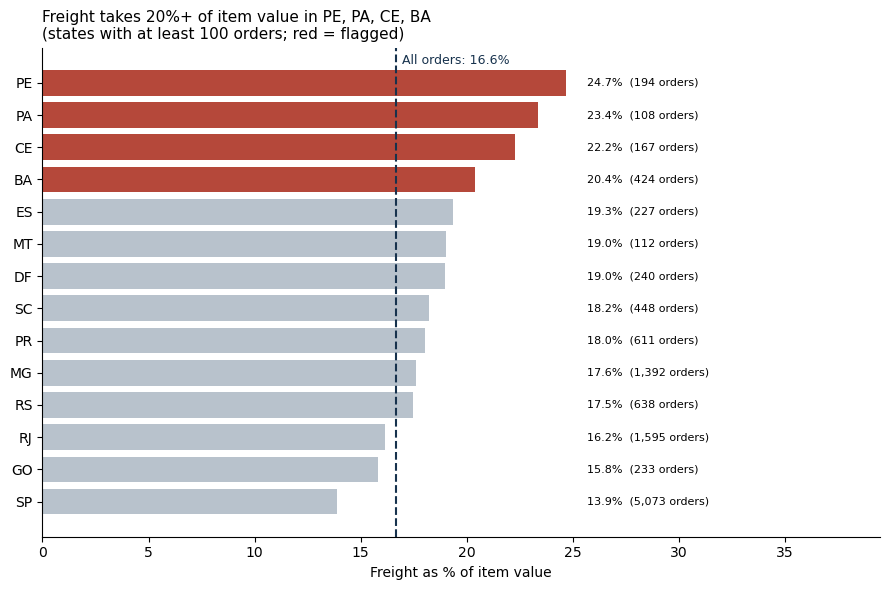

In [11]:
# Sort the trusted states so the biggest freight ratio is at the top of the chart.
plot_data = trusted.sort_values("freight_ratio", ascending=True)
colors = ["#B5483A" if is_flagged else "#B8C2CC" for is_flagged in plot_data["flag"]]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_data.index, plot_data["freight_ratio"] * 100, color=colors)
ax.axvline(overall_ratio * 100, color="#17324D", linestyle="--", linewidth=1.5)
ax.text(overall_ratio * 100 + 0.3, len(plot_data) - 0.4, f"All orders: {overall_ratio:.1%}", color="#17324D", fontsize=9)
for position, (state, row) in enumerate(plot_data.iterrows()):
    ax.text(plot_data["freight_ratio"].max() * 100 + 1, position, f"{row['freight_ratio']:.1%}  ({int(row['orders']):,} orders)", va="center", fontsize=8)

ax.set_title(f"Freight takes {HIGH_RATIO:.0%}+ of item value in {', '.join(flagged.index)}\n(states with at least {MIN_ORDERS} orders; red = flagged)", fontsize=11, loc="left")
ax.set_xlabel("Freight as % of item value")
ax.set_xlim(0, plot_data["freight_ratio"].max() * 100 * 1.6)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("freight_pressure_by_state.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Presentation notes

**Three findings** 

1. **Shipping is a large slice of what customers pay.** Across all 12,000 orders, freight is **16.6%** of item value (272,501 freight on 1,637,360 item value), and the typical single order pays **22.9%** because cheap orders carry a bigger share.
2. **Pressure is highest in the north-east and north.** **PE (24.7%), PA (23.4%), CE (22.2%) and BA (20.4%)** are flagged: at least 100 orders each and freight at least 20% of item value. Their average freight per order is roughly 31 to 44 (in the data's currency units), against **17** in SP.
3. **The biggest market is the cheapest to serve.** SP has **42%** of orders and the lowest freight ratio (**13.9%**), so the cost problem sits in the smaller, further states and is easy to miss in national averages.


**Limitation:** the data has no weight, size or distance, so I cannot say **why** freight is high in a state; it is a 12,000-order sample from Oct 2016 to Aug 2018; and the ratio is much higher for cheap orders (the cheapest quarter of orders has a median ratio of 51%, the most expensive quarter 10%), so a state can look costly simply because its customers buy cheaper items.

**Recommended next action (testable):** in PE, PA, CE and BA, test a **minimum order value or small-order shipping fee** for 4 weeks against similar control states, and measure the freight ratio, order volume and conversion.

**AI use disclosure:** AI helped write the first draft of the code. we checked the joins with the validation cells and checked the numbers before presenting.